# Import

In [20]:
from collections import defaultdict
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from IPython.display import display

import warnings

from mlxtend.frequent_patterns import fpgrowth as mlxtend_fpgrowth
from mlxtend.preprocessing import TransactionEncoder

# Đọc data

In [21]:
# Đọc lại đúng các file đã lưu từ notebook 01, không dùng biến cũ trong kernel.
X_train_model = pd.read_pickle("04_output/02_clean_data/X_train_model.pkl")
X_test_model = pd.read_pickle("04_output/02_clean_data/X_test_model.pkl")
y_train = pd.read_pickle("04_output/02_clean_data/y_train.pkl")
y_test = pd.read_pickle("04_output/02_clean_data/y_test.pkl")
arm_train = pd.read_pickle("04_output/02_clean_data/arm_train.pkl")
arm_test = pd.read_pickle("04_output/02_clean_data/arm_test.pkl")

selected_features = X_train_model.columns.tolist()
print("Các feature đã chọn:", selected_features)
RANDOM_STATE = 42

print("Train/Test:", X_train_model.shape, X_test_model.shape)
print("Tỷ lệ attack:", round(y_train.mean(), 4), "/", round(y_test.mean(), 4))

Các feature đã chọn: ['bwd_pkt_len_mean', 'bwd_subflow_bytes_mean', 'pkt_len_max', 'fwd_pkt_hdr_len_tot', 'flag_ack', 'fwd_pkt_len_max', 'fwd_pkt_len_mean', 'fwd_subflow_bytes_mean', 'fwd_pkt_len_tot', 'bwd_pkt_hdr_len_tot', 'bwd_tcp_init_win_bytes', 'iat_max', 'fwd_iat_max', 'fwd_tcp_init_win_bytes', 'bwd_pkt_len_std', 'flag_SYN', 'bytes_per_s', 'bwd_pkt_per_s', 'fwd_pkt_len_std', 'bwd_iat_max', 'fwd_subflow_pkt_mean', 'fwd_pkt_cnt', 'down_up_ratio', 'fwd_iat_std', 'fwd_non_empty_pkt_cnt', 'bwd_pkt_cnt', 'bwd_subflow_pkt_mean', 'bwd_non_empty_pkt_cnt', 'iat_std', 'bwd_pkt_hdr_len_min', 'pkt_len_min', 'ip_prot', 'iat_min', 'flag_psh', 'bwd_iat_min', 'fwd_iat_min', 'bwd_iat_std', 'bwd_bulk_bytes_mean', 'flag_rst']
Train/Test: (1464101, 39) (371127, 39)
Tỷ lệ attack: 0.2415 / 0.2371


# Khai phá luật kết hợp

In [22]:
MINING_SIZE = len(y_train)
MIN_SUPPORT = 0.02
MIN_CONFIDENCE = 0.55

# Vì eda đã sort sẵn MI từ lớn đến nhỏ rồi nên có thể dùng trực tiếp
ARM_FEATURE_COUNT = 30
if len(selected_features) < ARM_FEATURE_COUNT:
    raise ValueError("Cần ít nhất 30 feature từ notebook EDA để so sánh luật.")
arm_cols = selected_features[:ARM_FEATURE_COUNT]
missing_train = set(arm_cols) - set(arm_train.columns)
missing_test = set(arm_cols) - set(arm_test.columns)
if missing_train or missing_test:
    raise ValueError(
        f"Bảng item không khớp feature đã chọn: train thiếu {sorted(missing_train)}, "
        f"test thiếu {sorted(missing_test)}"
    )
if len(arm_cols) < 5:
    raise ValueError("Cần ít nhất 5 thuộc tính rời rạc hóa để khai phá luật.")

if len(y_train) > MINING_SIZE:
    mining_idx, _ = train_test_split(
        y_train.index, train_size=MINING_SIZE,
        stratify=y_train, random_state=RANDOM_STATE,
    )
else:
    mining_idx = y_train.index

# Biến dữ liệu thành giao dịch
basket = arm_train.loc[mining_idx, arm_cols]
transactions = [
    frozenset([*row, f"class={int(label)}"])
    for row, label in zip(basket.astype(str).itertuples(index=False, name=None),
                          y_train.loc[mining_idx])
]
MIN_COUNT = int(np.ceil(MIN_SUPPORT * len(transactions)))

print("Thuộc tính giao dịch:", arm_cols)
print("Số giao dịch:", len(transactions), "| Ngưỡng support:", MIN_COUNT)

Thuộc tính giao dịch: ['bwd_pkt_len_mean', 'bwd_subflow_bytes_mean', 'pkt_len_max', 'fwd_pkt_hdr_len_tot', 'flag_ack', 'fwd_pkt_len_max', 'fwd_pkt_len_mean', 'fwd_subflow_bytes_mean', 'fwd_pkt_len_tot', 'bwd_pkt_hdr_len_tot', 'bwd_tcp_init_win_bytes', 'iat_max', 'fwd_iat_max', 'fwd_tcp_init_win_bytes', 'bwd_pkt_len_std', 'flag_SYN', 'bytes_per_s', 'bwd_pkt_per_s', 'fwd_pkt_len_std', 'bwd_iat_max', 'fwd_subflow_pkt_mean', 'fwd_pkt_cnt', 'down_up_ratio', 'fwd_iat_std', 'fwd_non_empty_pkt_cnt', 'bwd_pkt_cnt', 'bwd_subflow_pkt_mean', 'bwd_non_empty_pkt_cnt', 'iat_std', 'bwd_pkt_hdr_len_min']
Số giao dịch: 1464101 | Ngưỡng support: 29283


## Giao dịch chứa tập mục

In [23]:
def make_vertical(rows):
    vertical = defaultdict(set)
    for tid, row in enumerate(rows):
        for item in row:
            vertical[item].add(tid)
    return dict(vertical)


def matching_tids(items, vertical):
    sets = [vertical[item] for item in items]
    if not sets:
        return set()
    result = sets[0].copy()
    for tids in sets[1:]:
        result.intersection_update(tids)
    return result


vertical = make_vertical(transactions)
print("Số item khác nhau:", len(vertical))


Số item khác nhau: 116


## FP-Growth

In [24]:
import warnings

from mlxtend.frequent_patterns import fpgrowth as mlxtend_fpgrowth
from mlxtend.preprocessing import TransactionEncoder


def fp_growth_target(rows, min_count, target_item="class=1", max_len=3):
    """Trả về {frozenset(items): support_count} cho các tập chứa target_item."""
    if min_count < 1 or max_len < 1:
        raise ValueError("min_count và max_len phải là số nguyên dương")

    target_rows = [
        [item for item in row if item != target_item]
        for row in rows if target_item in row
    ]
    target_count = len(target_rows)
    if target_count < min_count:
        return {}

    result = {frozenset((target_item,)): target_count}
    if max_len == 1 or not any(target_rows):
        return result

    encoder = TransactionEncoder()
    matrix = encoder.fit(target_rows).transform(target_rows, sparse=True)
    with warnings.catch_warnings():
        warnings.filterwarnings(
            "ignore", message="Allowing arbitrary scalar fill_value", category=FutureWarning
        )
        one_hot = pd.DataFrame.sparse.from_spmatrix(matrix, columns=encoder.columns_)

    patterns = mlxtend_fpgrowth(
        one_hot,
        min_support=min_count / target_count,
        use_colnames=True,
        max_len=max_len - 1,
    )
    result.update({
        itemset | {target_item}: int(round(support * target_count))
        for support, itemset in patterns.itertuples(index=False, name=None)
    })
    return result


sets_fp = fp_growth_target(transactions, MIN_COUNT, target_item="class=1", max_len=3)
print("Số tập mục FP-Growth chứa class=1:", len(sets_fp))


Số tập mục FP-Growth chứa class=1: 1268


## CHARM

In [25]:
def charm_closed(vertical, min_count, max_prefix_len=3):
    nodes = [
        (frozenset([item]), tids.copy())
        for item, tids in vertical.items()
        if len(tids) >= min_count
    ]
    closed = {}

    def extend(nodes):
        nodes.sort(key=lambda pair: (len(pair[1]), tuple(sorted(pair[0]))))
        i = 0
        while i < len(nodes):
            xi, ti = nodes[i]
            children = []
            j = i + 1
            while j < len(nodes):
                xj, tj = nodes[j]
                both = ti & tj
                if len(both) < min_count:
                    j += 1
                    continue

                merged = xi | xj
                if ti == tj:
                    # Hai tập xuất hiện trên đúng cùng giao dịch.
                    xi = merged
                    children = [(x | xj, t) for x, t in children]
                    nodes.pop(j)
                elif ti < tj:
                    # Mọi giao dịch có xi cũng có xj.
                    xi = merged
                    children = [(x | xj, t) for x, t in children]
                    j += 1
                elif ti > tj:
                    if len(merged) <= max_prefix_len:
                        children.append((merged, both))
                    nodes.pop(j)
                else:
                    if len(merged) <= max_prefix_len:
                        children.append((merged, both))
                    j += 1

            closure = frozenset(xi | {
                item for item, tids in vertical.items() if ti <= tids
            })
            closed[closure] = len(ti)
            if children:
                extend(children)
            i += 1

    extend(nodes)
    return closed


sets_charm = charm_closed(vertical, MIN_COUNT)
print("Số tập mục đóng CHARM:", len(sets_charm))

Số tập mục đóng CHARM: 21352


## Chọn 3 luật cho mỗi phương pháp

In [26]:
def candidate_rules(itemsets, vertical, n):
    base_attack = len(vertical["class=1"]) / n
    rows = []
    for pattern, count in itemsets.items():
        if "class=1" not in pattern or "class=0" in pattern:
            continue
        antecedent = pattern - {"class=1"}
        if not 1 <= len(antecedent) <= 2:
            continue
        tids = matching_tids(antecedent, vertical)
        confidence = count / len(tids)
        lift = confidence / base_attack
        if confidence >= MIN_CONFIDENCE and lift > 1:
            rows.append({
                "antecedent": antecedent, "tids": tids,
                "support": count / n, "coverage": len(tids) / n,
                "confidence": confidence, "lift": lift,
            })
    return rows


def select_three(candidates):
    selected = []
    covered = set()
    remaining = candidates.copy()
    while remaining and len(selected) < 3:
        best = max(remaining, key=lambda row: (
            len(row["tids"] - covered),
            row["confidence"], row["lift"], tuple(sorted(row["antecedent"])),
        ))
        selected.append(best)
        covered.update(best["tids"])
        remaining.remove(best)
    if len(selected) < 3:
        raise ValueError("Chưa có đủ 3 luật attack. Giảm MIN_SUPPORT hoặc MIN_CONFIDENCE rồi chạy lại trên train.")
    return selected


rules_fp = select_three(candidate_rules(sets_fp, vertical, len(transactions)))
rules_charm = select_three(candidate_rules(sets_charm, vertical, len(transactions)))


def rule_flags(items, rules):
    flags = pd.DataFrame(index=items.index)
    for i, rule in enumerate(rules, 1):
        match = pd.Series(True, index=items.index)
        for item in rule["antecedent"]:
            col = item.split("=", 1)[0]
            match &= items[col].astype(str).eq(item)
        flags[f"Rule_{i}"] = match.astype("int8")
    return flags


def describe_rules(rules, method, items, labels):
    flags = rule_flags(items, rules)
    base_attack = labels.mean()
    rows = []
    for i, rule in enumerate(rules, 1):
        mask = flags[f"Rule_{i}"].astype(bool)
        coverage = mask.mean()
        support = (mask & labels.eq(1)).mean()
        confidence = support / coverage if coverage else 0
        rows.append({
            "Phương pháp": method, "Luật": f"Rule_{i}",
            "Tiền đề": " & ".join(sorted(rule["antecedent"])),
            "Kết luận": "attack", "Coverage": coverage,
            "Support": support, "Confidence": confidence,
            "Lift": confidence / base_attack,
        })
    return pd.DataFrame(rows), flags


table_fp, flags_train_fp = describe_rules(rules_fp, "FP-Growth", arm_train, y_train)
table_charm, flags_train_charm = describe_rules(rules_charm, "CHARM", arm_train, y_train)
rules_table = pd.concat([table_fp, table_charm], ignore_index=True)
display(rules_table.round(4))
rules_table.to_csv("04_output/03_association_classification/association_rules.csv", index=False)

,Phương pháp,Luật,Tiền đề,Kết luận,Coverage,Support,Confidence,Lift
0,FP-Growth,Rule_1,"fwd_pkt_hdr_len_tot=(26, 146]",attack,0.2866,0.1829,0.6379,2.6413
1,FP-Growth,Rule_2,"bwd_pkt_per_s=(1.49110949039, 4839.10253906] &...",attack,0.2397,0.1416,0.5908,2.4463
2,FP-Growth,Rule_3,fwd_subflow_pkt_mean=<= 1.50757598877 & fwd_tc...,attack,0.1583,0.1083,0.6844,2.8338
3,CHARM,Rule_1,"fwd_pkt_hdr_len_tot=(26, 146] & fwd_tcp_init_w...",attack,0.2499,0.1829,0.7317,3.0296
4,CHARM,Rule_2,fwd_subflow_pkt_mean=<= 1.50757598877 & fwd_tc...,attack,0.1583,0.1083,0.6844,2.8338
5,CHARM,Rule_3,fwd_tcp_init_win_bytes=positive & iat_std=(426...,attack,0.1401,0.0994,0.7097,2.9384


## Truy vết từng lượt chọn luật

In [27]:
trace_rows = []
for method, rules in [
    ("FP-Growth", rules_fp),
    ("CHARM", rules_charm),
]:
    covered = set()
    for turn, rule in enumerate(rules, 1):
        new_tids = rule["tids"] - covered
        covered.update(rule["tids"])
        consequent = rule.get("consequent", "attack").removeprefix("class=")
        trace_rows.append({
            "Phương pháp": method,
            "Lượt": turn,
            "Luật chọn": " & ".join(sorted(rule["antecedent"])) + " ⇒ " + consequent,
            "Phủ thêm (%)": 100 * len(new_tids) / len(transactions),
            "Phủ chung sau lượt (%)": 100 * len(covered) / len(transactions),
            "Confidence": rule["confidence"],
            "Lift": rule["lift"],
        })

selection_trace = pd.DataFrame(trace_rows)
display(selection_trace.round(3))
selection_trace.to_csv("04_output/03_association_classification/rule_selection_trace.csv", index=False)


,Phương pháp,Lượt,Luật chọn,Phủ thêm (%),Phủ chung sau lượt (%),Confidence,Lift
0,FP-Growth,1,"fwd_pkt_hdr_len_tot=(26, 146] ⇒ attack",28.665,28.665,0.638,2.641
1,FP-Growth,2,"bwd_pkt_per_s=(1.49110949039, 4839.10253906] &...",8.419,37.084,0.591,2.446
2,FP-Growth,3,fwd_subflow_pkt_mean=<= 1.50757598877 & fwd_tc...,6.715,43.799,0.684,2.834
3,CHARM,1,"fwd_pkt_hdr_len_tot=(26, 146] & fwd_tcp_init_w...",24.991,24.991,0.732,3.030
4,CHARM,2,fwd_subflow_pkt_mean=<= 1.50757598877 & fwd_tc...,6.719,31.710,0.684,2.834
5,CHARM,3,fwd_tcp_init_win_bytes=positive & iat_std=(426...,3.938,35.648,0.710,2.938


## Bảng nội dung luật và đối chiếu hai phương pháp


In [28]:
rule_expressions = rules_table[["Phương pháp", "Luật", "Tiền đề", "Kết luận"]].copy()
rule_expressions["Luật kết hợp"] = (
    rule_expressions["Tiền đề"] + " ⇒ " + rule_expressions["Kết luận"]
)
rule_expressions = rule_expressions[["Phương pháp", "Luật", "Luật kết hợp"]]
display(rule_expressions)
rule_expressions.to_csv("04_output/03_association_classification/rule_expressions.csv", index=False)


,Phương pháp,Luật,Luật kết hợp
0,FP-Growth,Rule_1,"fwd_pkt_hdr_len_tot=(26, 146] ⇒ attack"
1,FP-Growth,Rule_2,"bwd_pkt_per_s=(1.49110949039, 4839.10253906] &..."
2,FP-Growth,Rule_3,fwd_subflow_pkt_mean=<= 1.50757598877 & fwd_tc...
3,CHARM,Rule_1,"fwd_pkt_hdr_len_tot=(26, 146] & fwd_tcp_init_w..."
4,CHARM,Rule_2,fwd_subflow_pkt_mean=<= 1.50757598877 & fwd_tc...
5,CHARM,Rule_3,fwd_tcp_init_win_bytes=positive & iat_std=(426...


In [29]:
method_order = ["FP-Growth", "CHARM"]
method_rules = {}
for method in method_order:
    rows = rules_table.loc[
        rules_table["Phương pháp"] == method, ["Tiền đề", "Kết luận"]
    ]
    method_rules[method] = list(rows.itertuples(index=False, name=None))

comparison_rows = []
for left, right in combinations(method_order, 2):
    left_rules = method_rules[left]
    right_rules = method_rules[right]
    common = len(set(left_rules) & set(right_rules))
    comparison_rows.append({
        "So sánh": f"{left} / {right}",
        "Số luật trùng": f"{common}/3",
        "Cùng bộ 3 luật": "Có" if set(left_rules) == set(right_rules) else "Không",
        "Cùng thứ tự": "Có" if left_rules == right_rules else "Không",
    })

rule_comparison = pd.DataFrame(comparison_rows)
display(rule_comparison)
rule_comparison.to_csv("04_output/03_association_classification/rule_comparison.csv", index=False)


,So sánh,Số luật trùng,Cùng bộ 3 luật,Cùng thứ tự
0,FP-Growth / CHARM,1/3,Không,Không


## 5.3. So sánh hai phương pháp bằng độ phủ của luật

Coverage của một luật là tỷ lệ dòng train thỏa **tiền đề** của luật, không phụ thuộc nhãn của dòng. Độ phủ chung là tỷ lệ dòng thỏa ít nhất một trong ba luật, nên không cộng ba tỷ lệ riêng lẻ. Hai phương pháp được đánh giá trên cùng tập train, cùng ngưỡng support/confidence và cùng giới hạn 1–2 điều kiện mỗi luật. Hai bộ luật có thể khác nhau vì tập ứng viên CHARM chỉ gồm các tập đóng. Phương pháp có độ phủ cao hơn chỉ tốt hơn **theo ba luật đã chọn trên bộ dữ liệu và cấu hình này**, không phải kết luận chung cho mọi dữ liệu.


In [30]:
coverage_table = pd.DataFrame([
    {
        "Phương pháp": method,
        "Số dòng train": len(flags),
        "Luật 1 (%)": 100 * flags["Rule_1"].mean(),
        "Luật 2 (%)": 100 * flags["Rule_2"].mean(),
        "Luật 3 (%)": 100 * flags["Rule_3"].mean(),
        "Số dòng phủ chung": int(flags.any(axis=1).sum()),
        "Độ phủ chung (%)": 100 * flags.any(axis=1).mean(),
    }
    for method, flags in [
        ("FP-Growth", flags_train_fp),
        ("CHARM", flags_train_charm),
    ]
])
display(coverage_table.round(3))
coverage_table.to_csv("04_output/03_association_classification/rule_coverage.csv", index=False)

fp_coverage = coverage_table.set_index("Phương pháp").loc["FP-Growth", "Độ phủ chung (%)"]
charm_coverage = coverage_table.set_index("Phương pháp").loc["CHARM", "Độ phủ chung (%)"]
if method_rules["FP-Growth"] == method_rules["CHARM"]:
    print("Hai phương pháp chọn cùng ba luật; độ phủ bằng nhau.")
elif np.isclose(fp_coverage, charm_coverage):
    print("Hai bộ luật khác nhau nhưng độ phủ chung bằng nhau.")
else:
    better = "FP-Growth" if fp_coverage > charm_coverage else "CHARM"
    print(f"{better} phủ thêm {abs(fp_coverage - charm_coverage):.3f} điểm phần trăm.")


,Phương pháp,Số dòng train,Luật 1 (%),Luật 2 (%),Luật 3 (%),Số dòng phủ chung,Độ phủ chung (%)
0,FP-Growth,1464101,28.665,23.969,15.827,641264,43.799
1,CHARM,1464101,24.991,15.827,14.006,521930,35.648


FP-Growth phủ thêm 8.151 điểm phần trăm.


In [31]:
coverage_detail = []

for method, flags in [
    ("FP-Growth", flags_train_fp),
    ("CHARM", flags_train_charm)
]:
    matched = flags.any(axis=1)

    coverage_detail.append({
        "Phương pháp": method,
        "Coverage toàn bộ (%)": 100 * matched.mean(),
        "Coverage Attack (%)": 100 * matched[y_train.eq(1)].mean(),
        "Coverage Benign (%)": 100 * matched[y_train.eq(0)].mean(),
        "Precision của bộ luật (%)": (
            100 * y_train[matched].eq(1).mean()
            if matched.any() else 0
        )
    })

coverage_detail = pd.DataFrame(coverage_detail)
display(coverage_detail.round(3))


,Phương pháp,Coverage toàn bộ (%),Coverage Attack (%),Coverage Benign (%),Precision của bộ luật (%)
0,FP-Growth,43.799,97.63,26.659,53.835
1,CHARM,35.648,97.67,15.900,66.171


# Classification

### Chạy model

In [32]:
baseline_label = "Classification basic"
classification_rules = {
    "Classification + CHARM": rules_charm,
    "Classification + FP-Growth": rules_fp,
}
dataset_methods = {
    "Classification + CHARM": "CHARM",
    "Classification + FP-Growth": "FP-Growth",
}
flags_train_by_dataset = {
    "Classification + CHARM": flags_train_charm,
    "Classification + FP-Growth": flags_train_fp,
}

# Coverage của đúng bộ ba luật đưa vào từng kịch bản phân lớp.
classification_coverage = pd.DataFrame([
    {
        "Kịch bản phân lớp": dataset,
        "Phương pháp khai phá luật": dataset_methods[dataset],
        "Số dòng train được phủ": int(flags.any(axis=1).sum()),
        "Độ phủ chung train (%)": 100 * flags.any(axis=1).mean(),
    }
    for dataset, flags in flags_train_by_dataset.items()
])
display(classification_coverage.round(3))
classification_coverage.to_csv(
    "04_output/03_association_classification/classification_rule_coverage.csv",
    index=False,
)


def rule_source_features(rules):
    sources = {
        item.split("=", 1)[0]
        for rule in rules
        for item in rule["antecedent"]
    }
    return [col for col in selected_features if col in sources]


# Cùng mẫu train/test cho cả ba kịch bản, giữ feature gốc khi thêm luật.
MODEL_TRAIN_SIZE = 120_000
if len(y_train) > MODEL_TRAIN_SIZE:
    model_idx, _ = train_test_split(
        y_train.index, train_size=MODEL_TRAIN_SIZE,
        stratify=y_train, random_state=RANDOM_STATE,
    )
else:
    model_idx = y_train.index

X_train_basic = X_train_model.loc[model_idx].copy()
X_test_basic = X_test_model.copy()
y_train_fit = y_train.loc[model_idx]
datasets = {baseline_label: (X_train_basic, X_test_basic)}
for dataset, rules in classification_rules.items():
    X_fit = X_train_basic.join(flags_train_by_dataset[dataset].loc[model_idx])
    X_eval = X_test_basic.join(rule_flags(arm_test[arm_cols], rules))
    datasets[dataset] = (X_fit, X_eval)

for dataset, (X_fit, X_eval) in datasets.items():
    print(f"{dataset} train/test:", X_fit.shape, X_eval.shape)


,Kịch bản phân lớp,Phương pháp khai phá luật,Số dòng train được phủ,Độ phủ chung train (%)
0,Classification + CHARM,CHARM,521930,35.648
1,Classification + FP-Growth,FP-Growth,641264,43.799


Classification basic train/test: (120000, 39) (371127, 39)
Classification + CHARM train/test: (120000, 42) (371127, 42)
Classification + FP-Growth train/test: (120000, 42) (371127, 42)


## Ba luật xác định được

In [33]:
selected_rule_rows = []
for dataset, rules in classification_rules.items():
    for i, rule in enumerate(rules, 1):
        selected_rule_rows.append({
            "Kịch bản phân lớp": dataset,
            "Phương pháp": dataset_methods[dataset],
            "Luật": f"Rule_{i}",
            "Luật kết hợp": " & ".join(sorted(rule["antecedent"])) + " ⇒ attack",
            "Cột gốc trong tiền đề": ", ".join(rule_source_features([rule])),
        })
selected_rule_map = pd.DataFrame(selected_rule_rows)
display(selected_rule_map)
selected_rule_map.to_csv("04_output/03_association_classification/selected_rule_features.csv", index=False)

,Kịch bản phân lớp,Phương pháp,Luật,Luật kết hợp,Cột gốc trong tiền đề
0,Classification + CHARM,CHARM,Rule_1,"fwd_pkt_hdr_len_tot=(26, 146] & fwd_tcp_init_w...","fwd_pkt_hdr_len_tot, fwd_tcp_init_win_bytes"
1,Classification + CHARM,CHARM,Rule_2,fwd_subflow_pkt_mean=<= 1.50757598877 & fwd_tc...,"fwd_tcp_init_win_bytes, fwd_subflow_pkt_mean"
2,Classification + CHARM,CHARM,Rule_3,fwd_tcp_init_win_bytes=positive & iat_std=(426...,"fwd_tcp_init_win_bytes, iat_std"
3,Classification + FP-Growth,FP-Growth,Rule_1,"fwd_pkt_hdr_len_tot=(26, 146] ⇒ attack",fwd_pkt_hdr_len_tot
4,Classification + FP-Growth,FP-Growth,Rule_2,"bwd_pkt_per_s=(1.49110949039, 4839.10253906] &...","flag_ack, bwd_pkt_per_s"
5,Classification + FP-Growth,FP-Growth,Rule_3,fwd_subflow_pkt_mean=<= 1.50757598877 & fwd_tc...,"fwd_tcp_init_win_bytes, fwd_subflow_pkt_mean"


### Dữ liệu có thêm luật FP-Growth


In [34]:
# Minh họa cột gốc trong tiền đề cạnh ba cột luật FP-Growth.
rule_cols = ["Rule_1", "Rule_2", "Rule_3"]
source_cols = rule_source_features(rules_fp)
X_train_fp = datasets["Classification + FP-Growth"][0]

# Lấy vài dòng thỏa từng luật và vài dòng không thỏa luật nào.
example_idx = []
for col in rule_cols:
    example_idx.extend(X_train_fp.index[X_train_fp[col].eq(1)][:2])
example_idx.extend(X_train_fp.index[X_train_fp[rule_cols].eq(0).all(axis=1)][:2])
example_idx = list(dict.fromkeys(example_idx))
rule_example = X_train_fp.loc[example_idx, source_cols + rule_cols]
display(rule_example)
rule_example.to_csv("04_output/03_association_classification/rule_feature_fpgrowth.csv", index=True)


,fwd_pkt_hdr_len_tot,flag_ack,fwd_tcp_init_win_bytes,bwd_pkt_per_s,fwd_subflow_pkt_mean,Rule_1,Rule_2,Rule_3
270141,40,1,29200,22727.272727,1.000000,1,0,1
948805,132,8,8192,0.517603,3.000000,1,0,0
691706,396,19,65535,137.306055,12.000000,0,1,0
1383184,2828,211,65535,3.170020,44.000000,0,1,0
1427807,328,19,29200,0.153562,1.250000,0,0,1
984633,16,0,-1,63.987714,2.000000,0,0,0
552685,1384,94,29200,0.462716,4.777778,0,0,0


### Dữ liệu có thêm luật CHARM

In [ ]:
# Minh họa cột gốc trong tiền đề cạnh ba cột luật FP-Growth.
rule_cols = ["Rule_1", "Rule_2", "Rule_3"]
source_cols = rule_source_features(rules_fp)
X_train_fp = datasets["Classification + CHARM"][0]

# Lấy vài dòng thỏa từng luật và vài dòng không thỏa luật nào.
example_idx = []
for col in rule_cols:
    example_idx.extend(X_train_fp.index[X_train_fp[col].eq(1)][:2])
example_idx.extend(X_train_fp.index[X_train_fp[rule_cols].eq(0).all(axis=1)][:2])
example_idx = list(dict.fromkeys(example_idx))
rule_example = X_train_fp.loc[example_idx, source_cols + rule_cols]
display(rule_example)
rule_example.to_csv("04_output/03_association_classification/rule_feature_charm.csv", index=True)

# Phân lớp

In [35]:
def build_models():
    return {
        "Logistic Regression": make_pipeline(
            StandardScaler(), LogisticRegression(max_iter=500, random_state=RANDOM_STATE)
        ),
        "Decision Tree": DecisionTreeClassifier(
            max_depth=12, min_samples_leaf=20, random_state=RANDOM_STATE
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=80, max_depth=16, min_samples_leaf=10,
            n_jobs=-1, random_state=RANDOM_STATE,
        ),
    }


results_rows = []
confusion_rows = []
for dataset, (X_fit, X_eval) in datasets.items():
    for name, model in build_models().items():
        print("Đang chạy:", dataset, name)
        model.fit(X_fit, y_train_fit)
        pred = model.predict(X_eval)
        results_rows.append({
            "Kịch bản phân lớp": dataset, "Mô hình": name,
            "Accuracy": accuracy_score(y_test, pred),
            "Precision (attack)": precision_score(y_test, pred, zero_division=0),
            "Recall (attack)": recall_score(y_test, pred, zero_division=0),
            "F1 (attack)": f1_score(y_test, pred, zero_division=0),
        })
        matrix = confusion_matrix(y_test, pred, labels=[0, 1])
        confusion_rows.append({
            "Kịch bản phân lớp": dataset, "Mô hình": name,
            "TN": int(matrix[0, 0]), "FP": int(matrix[0, 1]),
            "FN": int(matrix[1, 0]), "TP": int(matrix[1, 1]),
        })

results = pd.DataFrame(results_rows)
confusion_table = pd.DataFrame(confusion_rows)
results.to_csv("04_output/03_association_classification/classification_results.csv", index=False)
confusion_table.to_csv("04_output/03_association_classification/confusion_matrices.csv", index=False)

Đang chạy: Classification basic Logistic Regression
Đang chạy: Classification basic Decision Tree
Đang chạy: Classification basic Random Forest
Đang chạy: Classification + CHARM Logistic Regression
Đang chạy: Classification + CHARM Decision Tree
Đang chạy: Classification + CHARM Random Forest
Đang chạy: Classification + FP-Growth Logistic Regression
Đang chạy: Classification + FP-Growth Decision Tree
Đang chạy: Classification + FP-Growth Random Forest


## Ma trận nhầm lẫn

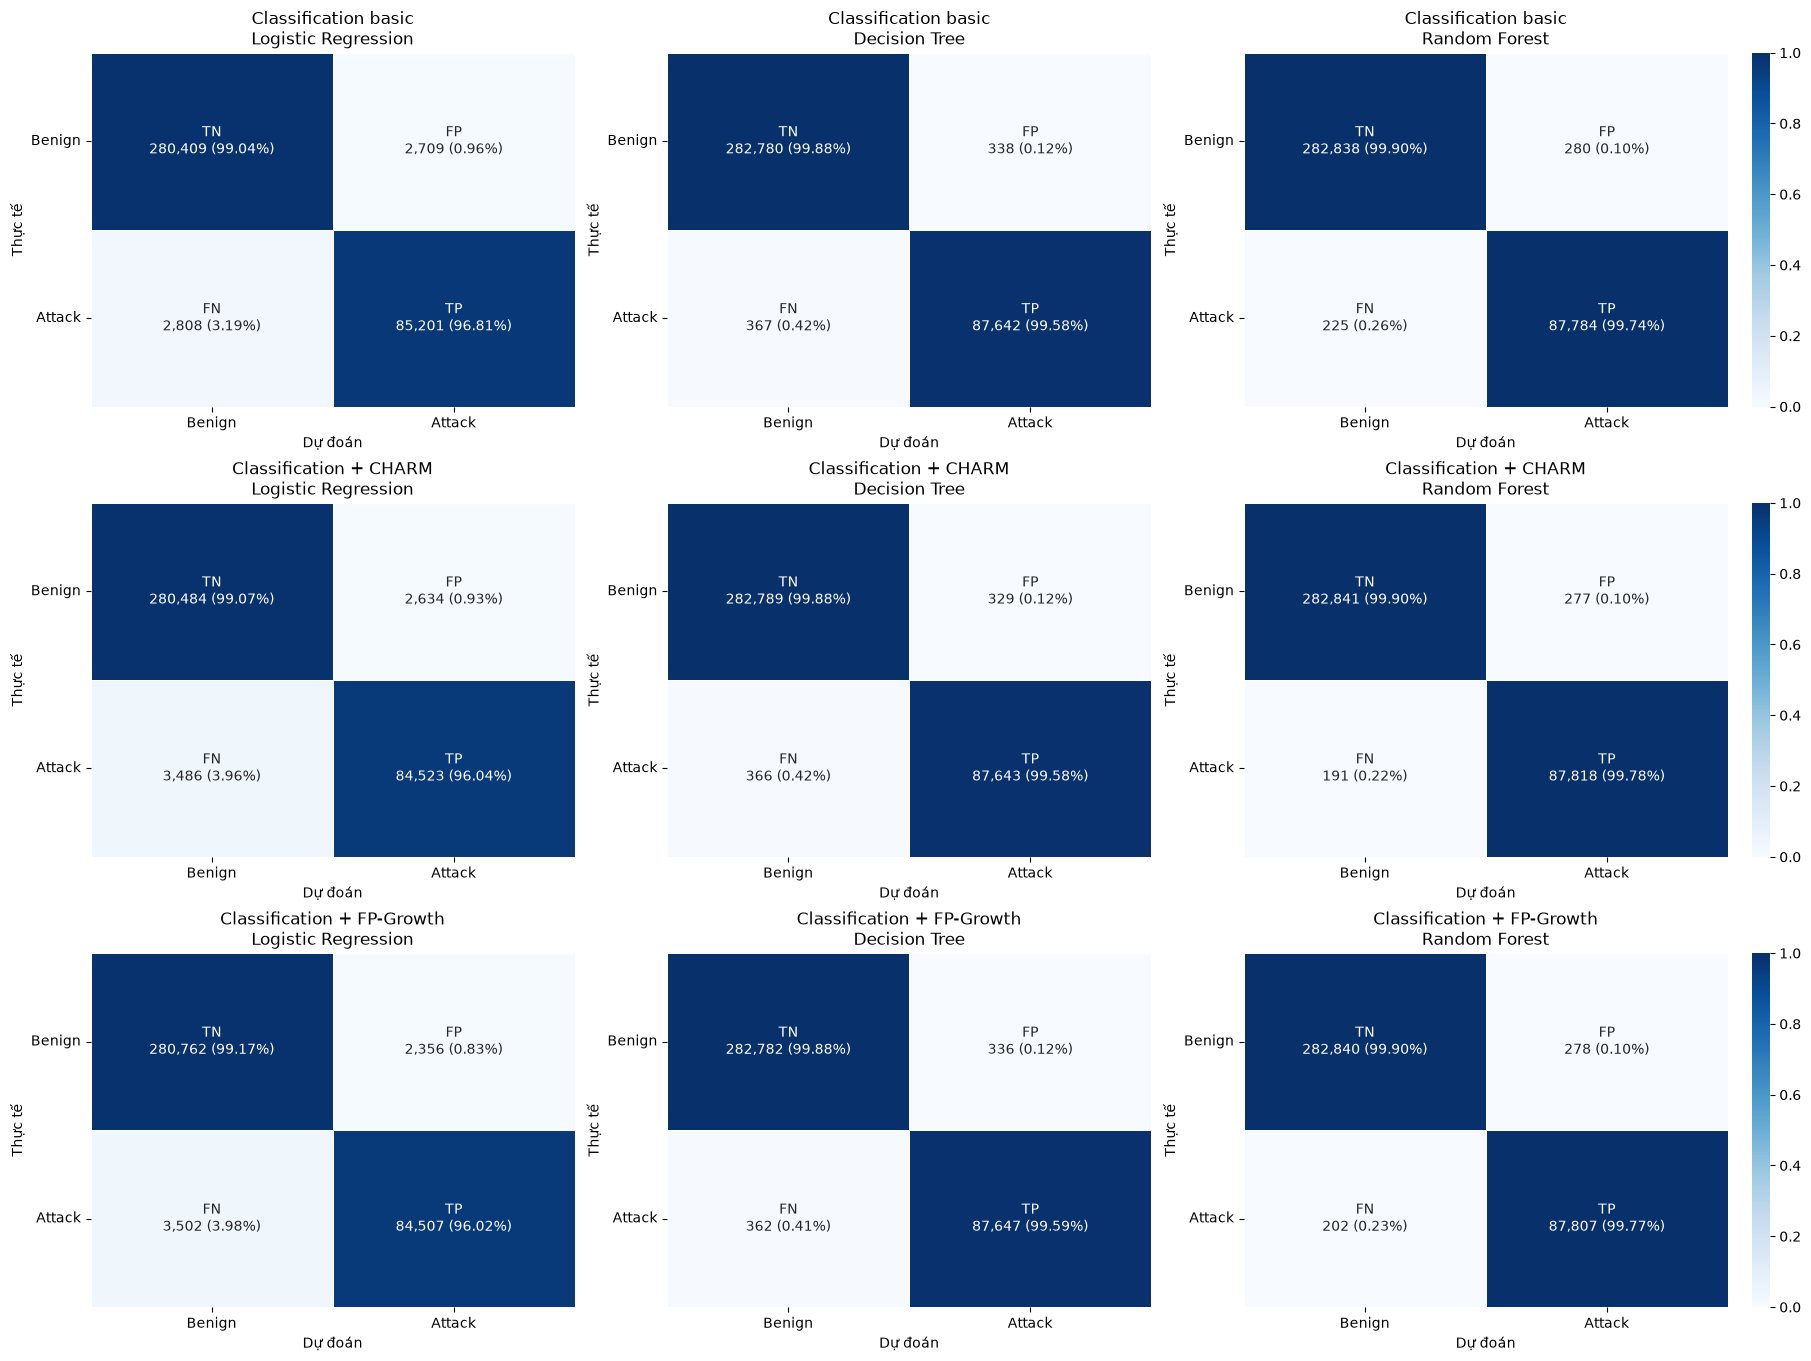

In [36]:
model_order = results["Mô hình"].drop_duplicates().tolist()
fig, axes = plt.subplots(len(datasets), len(model_order), figsize=(18, 4.5 * len(datasets)), constrained_layout=True)

for row, dataset in enumerate(datasets):
    for col, model_name in enumerate(model_order):
        record = confusion_table.loc[
            (confusion_table["Kịch bản phân lớp"] == dataset)
            & (confusion_table["Mô hình"] == model_name)
        ].iloc[0]
        matrix = np.array([
            [record["TN"], record["FP"]],
            [record["FN"], record["TP"]],
        ], dtype=int)
        ratio = matrix / matrix.sum(axis=1, keepdims=True)
        names = [["TN", "FP"], ["FN", "TP"]]
        labels = np.array([
            [f"{names[i][j]}\n{matrix[i, j]:,} ({ratio[i, j]:.2%})" for j in range(2)]
            for i in range(2)
        ])

        sns.heatmap(
            ratio, ax=axes[row, col], annot=labels, fmt="",
            cmap="Blues", vmin=0, vmax=1, linewidths=.5,
            linecolor="white", cbar=(col == 2),
            annot_kws={"fontsize": 10},
            xticklabels=["Benign", "Attack"],
            yticklabels=["Benign", "Attack"],
        )
        axes[row, col].set_title(f"{dataset}\n{model_name}")
        axes[row, col].set_xlabel("Dự đoán")
        axes[row, col].set_ylabel("Thực tế")
        axes[row, col].tick_params(axis="y", rotation=0)

plt.savefig("04_output/03_association_classification/confusion_matrices.png", dpi=160, bbox_inches="tight")
plt.show()

## Precision, Recall, F1 và Accuracy

In [37]:
metric_cols = ["Accuracy", "Precision (attack)", "Recall (attack)", "F1 (attack)"]
scenario_order = {dataset: i for i, dataset in enumerate(datasets)}
score_table = (
    results.assign(_scenario_order=results["Kịch bản phân lớp"].map(scenario_order))
    .sort_values(["Mô hình", "_scenario_order"])
    .drop(columns="_scenario_order")
    .copy()
)


display(
    score_table.style.highlight_max(
        axis=0,
        color="yellow",
        subset=score_table.select_dtypes(include="number").columns
    )
)

,Kịch bản phân lớp,Mô hình,Accuracy,Precision (attack),Recall (attack),F1 (attack)
1,Classification basic,Decision Tree,0.998100,0.996158,0.995830,0.995994
4,Classification + CHARM,Decision Tree,0.998127,0.996260,0.995841,0.996051
7,Classification + FP-Growth,Decision Tree,0.998119,0.996181,0.995887,0.996034
0,Classification basic,Logistic Regression,0.985134,0.969184,0.968094,0.968639
3,Classification + CHARM,Logistic Regression,0.983510,0.969779,0.960390,0.965062
6,Classification + FP-Growth,Logistic Regression,0.984216,0.972877,0.960209,0.966501
2,Classification basic,Random Forest,0.998639,0.996820,0.997443,0.997132
5,Classification + CHARM,Random Forest,0.998739,0.996856,0.997830,0.997342
8,Classification + FP-Growth,Random Forest,0.998707,0.996844,0.997705,0.997274


## Mức thay metrics CHARM và FP-Growth

In [38]:
model_order = results["Mô hình"].drop_duplicates().tolist()
metric_cols = ["Accuracy", "Precision (attack)", "Recall (attack)", "F1 (attack)"]
d0 = results[results["Kịch bản phân lớp"] == baseline_label].set_index("Mô hình")
effect_rows = []
for dataset in list(datasets)[1:]:
    compared = results[results["Kịch bản phân lớp"] == dataset].set_index("Mô hình")
    for model_name in model_order:
        row = {"Kịch bản phân lớp": dataset, "Mô hình": model_name}
        for metric in metric_cols:
            row[f"Δ {metric} (điểm %)"] = 100 * (
                compared.loc[model_name, metric] - d0.loc[model_name, metric]
            )
        effect_rows.append(row)
effect = pd.DataFrame(effect_rows)

effect_display = effect.copy()
for col in effect.columns[2:]:
    effect_display[col] = effect_display[col].map(
        lambda value: "0.000" if abs(value) < .0005 else f"{value:+.3f}"
    )
display(effect_display)
effect.to_csv("04_output/03_association_classification/rule_feature_effect.csv", index=False)

,Kịch bản phân lớp,Mô hình,Δ Accuracy (điểm %),Δ Precision (attack) (điểm %),Δ Recall (attack) (điểm %),Δ F1 (attack) (điểm %)
0,Classification + CHARM,Logistic Regression,-0.162,+0.059,-0.770,-0.358
1,Classification + CHARM,Decision Tree,+0.003,+0.010,+0.001,+0.006
2,Classification + CHARM,Random Forest,+0.010,+0.004,+0.039,+0.021
3,Classification + FP-Growth,Logistic Regression,-0.092,+0.369,-0.789,-0.214
4,Classification + FP-Growth,Decision Tree,+0.002,+0.002,+0.006,+0.004
5,Classification + FP-Growth,Random Forest,+0.007,+0.002,+0.026,+0.014


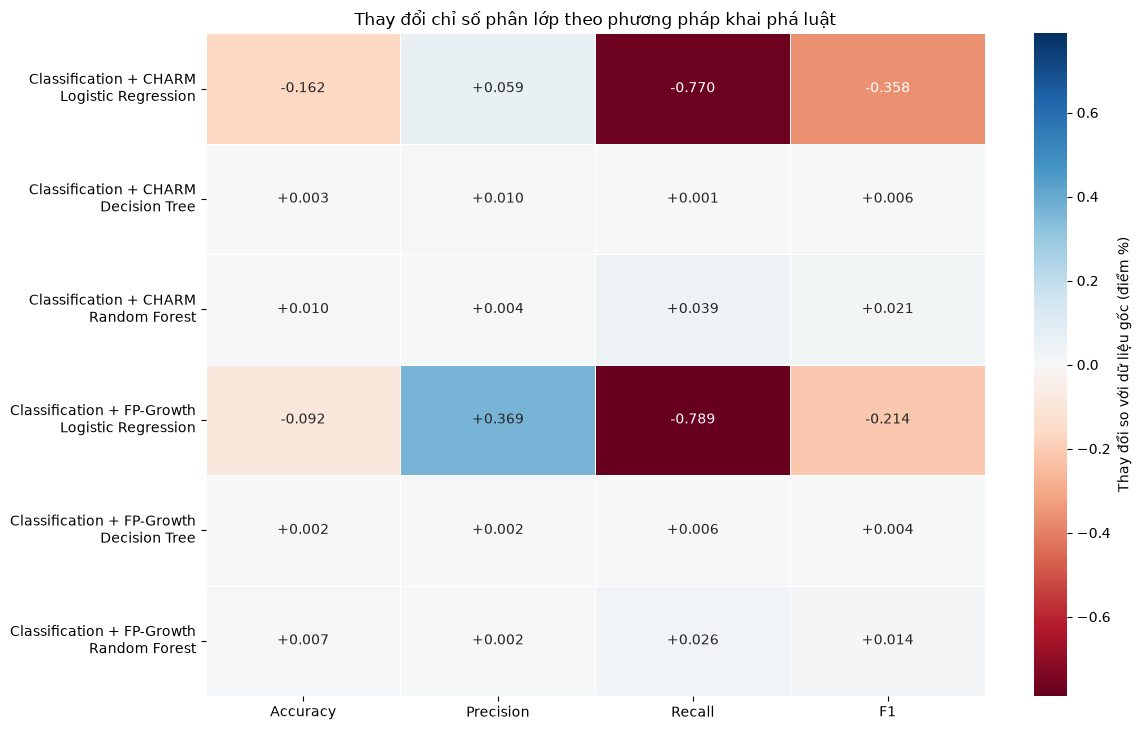

In [39]:
delta = effect.set_index(["Kịch bản phân lớp", "Mô hình"])
delta.columns = ["Accuracy", "Precision", "Recall", "F1"]
delta.index = [f"{scenario}\n{model}" for scenario, model in delta.index]
values = delta.to_numpy()
limit = np.abs(values).max()
annotations = np.array([
    ["0.000" if abs(value) < .0005 else f"{value:+.3f}" for value in row]
    for row in values
])

fig, ax = plt.subplots(figsize=(12, 2 + 0.9 * len(delta)))
sns.heatmap(
    delta, annot=annotations, fmt="", cmap="RdBu", center=0,
    vmin=-limit, vmax=limit, linewidths=.5, linecolor="white",
    cbar_kws={"label": "Thay đổi so với dữ liệu gốc (điểm %)"}, ax=ax,
)
ax.set_title("Thay đổi chỉ số phân lớp theo phương pháp khai phá luật")
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig("04_output/03_association_classification/metric_changes.png", dpi=160, bbox_inches="tight")
plt.show()